# Final solution: candidate detection and CatBoost


In [5]:
import json
import hashlib
import tempfile
from pathlib import Path
from itertools import combinations
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.feature import hog, graycomatrix, graycoprops
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from catboost import CatBoostClassifier, Pool
from joblib import Parallel, delayed, parallel_config
from tqdm import tqdm

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("forth_task/data")
OUTPUT_DIR = DATA_DIR.parent / "outputs/final_catboost"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
RANKING_PATH = DATA_DIR.parent / "outputs/candidate_model/boosting/feature_importance.csv"
N_WORKERS = 6
PADDING = (0,0.12)
MAX_LINES = 150
POSITIVE_IOU = 0.5
NEGATIVE_IOU = 0.2
NEGATIVES_PER_IMAGE = 60
TRAIN_IMAGE_LIMIT = None
VALIDATION_IMAGES = 50
TEST_IMAGES = 200
HORIZONTAL_FLIP = False
SEED = 42
train_paths = sorted((DATA_DIR / "photos/train").glob("*.jpg"))[:TRAIN_IMAGE_LIMIT]
val_paths = sorted(np.random.default_rng(123).choice(
    sorted((DATA_DIR / "photos/val").glob("*.jpg")),VALIDATION_IMAGES,replace=False))
test_paths = sorted(np.random.default_rng(2027).choice(
    sorted((DATA_DIR / "photos/test").glob("*.jpg")),TEST_IMAGES,replace=False))
print(f"Train: {len(train_paths)} images; validation: {len(val_paths)}; test: {len(test_paths)}")

Train: 70000 images; validation: 50; test: 200


In [6]:
def read_image(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def sign_boxes(path):
    label = DATA_DIR / "labels" / path.parent.name / f"{path.stem}.json"
    objects = json.loads(label.read_text())["frames"][0]["objects"]
    return np.asarray([
        [obj["box2d"][k] for k in ("x1", "y1", "x2", "y2")]
        for obj in objects
        if obj["category"] == "traffic sign" and "box2d" in obj
        and obj["box2d"]["x2"] > obj["box2d"]["x1"]
        and obj["box2d"]["y2"] > obj["box2d"]["y1"]
    ], dtype=float).reshape(-1, 4)


def iou(box, boxes):
    intersection = np.prod(np.maximum(0, np.minimum(box[2:], boxes[:, 2:]) -
                                      np.maximum(box[:2], boxes[:, :2])), axis=1)
    area = np.prod(box[2:] - box[:2])
    areas = np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)
    return intersection / (area + areas - intersection + 1e-9)

In [7]:
def rectangles_to_boxes(rectangles, image):
    height, width = image.shape[:2]
    boxes = set()
    for x, y, w, h in rectangles:
        if 4 <= w <= width * 0.6 and 6 <= h <= height * 0.6 and 0.2 <= w/h <= 6:
            for padding in PADDING:
                dx, dy = round(w * padding), round(h * padding)
                boxes.add((max(0, x-dx), max(0, y-dy),
                           min(width, x+w+dx), min(height, y+h+dy)))
    return np.asarray(sorted(boxes), dtype=float).reshape(-1, 4)


def hsv_candidates(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    masks = [
        cv2.inRange(hsv, (0, 70, 45), (12, 255, 255)) |
        cv2.inRange(hsv, (165, 70, 45), (179, 255, 255)),
        cv2.inRange(hsv, (15, 60, 45), (40, 255, 255)),
        cv2.inRange(hsv, (40, 55, 35), (140, 255, 255)),
        cv2.inRange(hsv, (0, 0, 150), (179, 65, 255))
    ]
    rectangles = []
    for mask in masks:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rectangles.extend(cv2.boundingRect(contour) for contour in contours)
    return rectangles_to_boxes(rectangles, image)


def mser_candidates(image):
    mser = cv2.MSER_create()
    mser.setMinArea(30)
    mser.setMaxArea(int(image.shape[0] * image.shape[1] * 0.08))
    _, regions = mser.detectRegions(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY))
    return rectangles_to_boxes(regions, image)


def shape_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    rectangles = []
    for low, high in [(30, 90), (70, 180)]:
        edges = cv2.Canny(gray, low, high)
        edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
        contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        for contour in contours:
            area = cv2.contourArea(contour)
            perimeter = cv2.arcLength(contour, True)
            if area < 20 or perimeter == 0:
                continue
            polygon = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
            circularity = 4 * np.pi * area / perimeter**2
            if cv2.isContourConvex(polygon) and (len(polygon) in (3, 4, 8) or circularity >= 0.7):
                rectangles.append(cv2.boundingRect(contour))
    return rectangles_to_boxes(rectangles, image)


def line_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 40, 120)
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=12,
                            minLineLength=8, maxLineGap=5)
    if lines is None:
        return np.empty((0, 4))
    segments = np.asarray(lines, dtype=float).reshape(-1, 4)
    vectors = segments[:, 2:] - segments[:, :2]
    lengths = np.linalg.norm(vectors, axis=1)
    order = np.argsort(lengths)[::-1][:MAX_LINES]
    segments, lengths = segments[order], lengths[order]
    rectangles = []
    for i, j in combinations(range(len(segments)), 2):
        first, second = segments[i].reshape(2, 2), segments[j].reshape(2, 2)
        direction = (first[1] - first[0]) / lengths[i]
        other = (second[1] - second[0]) / lengths[j]
        if abs(np.dot(direction, other)) < np.cos(np.deg2rad(10)):
            continue
        normal = np.array([-direction[1], direction[0]])
        distance = abs(np.dot(second.mean(axis=0) - first.mean(axis=0), normal))
        a, b = np.sort(first @ direction), np.sort(second @ direction)
        overlap = min(a[1], b[1]) - max(a[0], b[0])
        if 4 <= distance <= 250 and overlap >= 0.5 * min(lengths[i], lengths[j]):
            points = np.vstack([first, second]).astype(np.float32)
            rectangles.append(cv2.boundingRect(points))
    return rectangles_to_boxes(rectangles, image)


def merge_boxes(*groups):
    return np.unique(np.concatenate(groups, axis=0), axis=0)


def contrast_candidates(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return merge_boxes(hsv_candidates(enhanced), mser_candidates(enhanced),
                       shape_candidates(enhanced))


def adaptive_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    rectangles = []
    for block_size in (15, 31):
        for mode in (cv2.THRESH_BINARY, cv2.THRESH_BINARY_INV):
            mask = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         mode, block_size, 5)
            for kernel in ((1, 1), (9, 3), (3, 9)):
                joined = cv2.morphologyEx(mask, cv2.MORPH_CLOSE,
                                         np.ones((kernel[1], kernel[0]), np.uint8))
                contours, _ = cv2.findContours(joined, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
                for contour in contours:
                    x, y, w, h = cv2.boundingRect(contour)
                    fill = cv2.contourArea(contour) / max(w*h, 1)
                    if 0.15 <= fill <= 1 and w*h >= 20:
                        rectangles.append((x, y, w, h))
    return rectangles_to_boxes(rectangles, image)


def grouped_candidates(image, boxes):
    widths = boxes[:, 2] - boxes[:, 0]
    heights = boxes[:, 3] - boxes[:, 1]
    boxes = boxes[(widths <= 160) & (heights <= 100)]
    boxes = boxes[np.argsort(boxes[:, 0])]
    rectangles = []
    for i, first in enumerate(boxes):
        w1, h1 = first[2:] - first[:2]
        for second in boxes[i+1:]:
            if second[0] > first[2] + max(15, h1*2):
                break
            w2, h2 = second[2:] - second[:2]
            vertical_overlap = min(first[3], second[3]) - max(first[1], second[1])
            horizontal_overlap = min(first[2], second[2]) - max(first[0], second[0])
            horizontal_gap = max(0, second[0]-first[2])
            vertical_gap = max(0, max(first[1], second[1])-min(first[3], second[3]))
            aligned_row = (vertical_overlap >= 0.5*min(h1,h2)
                           and 0.4 <= h1/h2 <= 2.5
                           and horizontal_gap <= max(8, min(h1,h2)))
            aligned_column = (horizontal_overlap >= 0.5*min(w1,w2)
                              and 0.4 <= w1/w2 <= 2.5
                              and vertical_gap <= max(8, min(w1,w2)))
            if aligned_row or aligned_column:
                left, top = np.minimum(first[:2], second[:2])
                right, bottom = np.maximum(first[2:], second[2:])
                if (right-left)*(bottom-top) <= 30000:
                    rectangles.append((left, top, right-left, bottom-top))
    return rectangles_to_boxes(rectangles, image)


def upscaled_candidates(image):
    height, width = image.shape[:2]
    enlarged = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    boxes = merge_boxes(mser_candidates(enlarged), shape_candidates(enlarged)) / 2
    sizes = boxes[:, 2:] - boxes[:, :2]
    boxes = boxes[np.max(sizes, axis=1) <= 64]
    boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
    boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)
    return boxes


def candidate_groups(image):
    hsv = hsv_candidates(image)
    mser = mser_candidates(image)
    shapes = shape_candidates(image)
    lines = line_candidates(image)
    original = merge_boxes(hsv, mser, shapes, lines)
    contrast = contrast_candidates(image)
    adaptive = adaptive_candidates(image)
    grouped = grouped_candidates(image, merge_boxes(hsv, mser))
    upscaled = upscaled_candidates(image)
    return dict(HSV=hsv, MSER=mser, Shapes=shapes, Lines=lines,
                Baseline=merge_boxes(hsv, mser),
                Baseline_Shapes=merge_boxes(hsv, mser, shapes),
                Original_All=original, CLAHE=contrast, Adaptive=adaptive,
                Grouped=grouped, Upscaled=upscaled,
                Original_CLAHE=merge_boxes(original, contrast),
                Original_Adaptive=merge_boxes(original, adaptive),
                Original_Grouped=merge_boxes(original, grouped),
                Original_Upscaled=merge_boxes(original, upscaled),
                All=merge_boxes(original, contrast, adaptive, grouped, upscaled))

## Selected features and GLCM


In [8]:
ranking = pd.read_csv(RANKING_PATH)
ranked = ranking.sort_values(["AP_drop","mean_abs_contribution"],ascending=False,na_position="last")
selected_indices = np.unique(np.r_[ranked.head(128)["index"].to_numpy(dtype=int),np.arange(1764,1815)])
selected_names = [ranking.set_index("index").loc[i,"feature"] for i in selected_indices]
glcm_properties = ["contrast","dissimilarity","homogeneity","energy","correlation","ASM"]
glcm_names = [f"glcm_{prop}_d{distance}_a{angle}" for prop in glcm_properties
              for distance in (1,2) for angle in range(4)]
final_feature_names = selected_names+glcm_names
FEATURE_COUNT = len(final_feature_names)
print(f"Selected existing features: {len(selected_indices)}; GLCM: {len(glcm_names)}; total: {FEATURE_COUNT}")
display(ranked.head(20))
pd.DataFrame({"feature":final_feature_names}).to_csv(OUTPUT_DIR / "feature_names.csv",index=False)


def extract_crop(image,box):
    height,width=image.shape[:2]
    x1,y1=np.floor(box[:2]).astype(int)
    x2,y2=np.ceil(box[2:]).astype(int)
    x1,y1=np.clip(x1,0,width-1),np.clip(y1,0,height-1)
    x2,y2=np.clip(x2,x1+1,width),np.clip(y2,y1+1,height)
    crop=cv2.resize(image[y1:y2,x1:x2],(64,64))
    geometry=np.array([np.log((x2-x1)/(y2-y1)),(x2-x1)/width,(y2-y1)/height])
    return crop,geometry


def crop_features(crop,geometry):
    gray=cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)
    shape=hog(gray,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm="L2-Hys")
    hsv=cv2.cvtColor(crop,cv2.COLOR_RGB2HSV)
    color=np.concatenate([np.histogram(hsv[:,:,k],bins=16,range=(0,upper))[0]/4096
                          for k,upper in enumerate((180,256,256))])
    base=np.r_[shape,color,geometry].astype(np.float32)
    base/=max(np.linalg.norm(base),1e-9)
    matrix=graycomatrix(gray//8,distances=[1,2],angles=[0,np.pi/4,np.pi/2,3*np.pi/4],
                       levels=32,symmetric=True,normed=True)
    texture=np.concatenate([graycoprops(matrix,prop).ravel() for prop in glcm_properties])
    return np.r_[base[selected_indices],texture].astype(np.float32)


def augment_crop(crop,rng):
    crop=cv2.resize(crop,(72,72))
    top,bottom,left,right=rng.integers(0,3,size=4)
    crop=cv2.resize(crop[top:72-bottom,left:72-right],(64,64))
    rotation=cv2.getRotationMatrix2D((31.5,31.5),float(rng.uniform(-7,7)),1)
    crop=cv2.warpAffine(crop,rotation,(64,64),borderMode=cv2.BORDER_REFLECT_101)
    if HORIZONTAL_FLIP and rng.random()<0.15:
        crop=cv2.flip(crop,1)
    crop=crop.astype(np.float32)*rng.uniform(0.85,1.15)+rng.uniform(-15,15)
    if rng.random()<0.3:
        crop+=rng.normal(0,2,crop.shape)
    crop=np.clip(crop,0,255).astype(np.uint8)
    if rng.random()<0.25:
        crop=cv2.GaussianBlur(crop,(3,3),float(rng.uniform(0.3,0.8)))
    return crop


def label_candidates(boxes,truth):
    overlaps=np.array([iou(box,truth).max(initial=0) for box in boxes])
    labels=np.full(len(boxes),-1,dtype=int)
    labels[overlaps<NEGATIVE_IOU]=0
    labels[overlaps>=POSITIVE_IOU]=1
    return labels


def atomic_npz(destination,**arrays):
    with tempfile.NamedTemporaryFile(dir=destination.parent,suffix=".tmp.npz",delete=False) as file:
        temporary=Path(file.name)
        np.savez_compressed(file,**arrays)
    temporary.replace(destination)

Selected existing features: 164; GLCM: 48; total: 212


,index,feature,coefficient,mean_abs_contribution,AP_drop
17,1780,hsv_S_0,-3.287346,0.055756,0.020820
8,1781,hsv_S_1,-3.139204,0.059872,0.007811
117,1770,hsv_H_6,1.761893,0.009108,0.004728
39,1773,hsv_H_9,-2.466312,0.030988,0.003382
28,36,hog_b0_1_c0_0_o0,-1.597638,0.050050,0.003375
1,1782,hsv_S_2,-3.423338,0.067716,0.003022
9,22,hog_b0_0_c1_0_o4,-1.640691,0.057973,0.002801
41,1759,hog_b6_6_c1_1_o4,-1.055271,0.030244,0.002510
59,1771,hsv_H_7,2.375620,0.015822,0.002504
37,229,hog_b0_6_c0_1_o4,-1.160818,0.032615,0.002192


## Training candidates


In [9]:
import zipfile
import zlib
import cloudpickle

cache_id=hashlib.sha256(cloudpickle.dumps((candidate_groups,crop_features,selected_indices,
    PADDING,MAX_LINES,POSITIVE_IOU,NEGATIVE_IOU,NEGATIVES_PER_IMAGE))).hexdigest()[:12]
CACHE_DIR=OUTPUT_DIR / f"train_{cache_id}"
CACHE_DIR.mkdir(exist_ok=True)


def prepare_image(path):
    cv2.setNumThreads(1)
    destination=CACHE_DIR / f"{path.stem}.npz"
    labels=None
    if destination.exists():
        try:
            with np.load(destination) as data:
                features,labels,boxes=data["X"],data["y"],data["boxes"]
                if features.shape!=(len(labels),FEATURE_COUNT) or boxes.shape!=(len(labels),4):
                    labels=None
        except (KeyError,ValueError,OSError,EOFError,zipfile.BadZipFile,zlib.error):
            labels=None
    if labels is None:
        rng=np.random.default_rng(int(hashlib.sha256(path.stem.encode()).hexdigest()[:8],16))
        image=read_image(path)
        boxes=candidate_groups(image)["All"]
        labels=label_candidates(boxes,sign_boxes(path))
        positive=np.flatnonzero(labels==1)
        negative=np.flatnonzero(labels==0)
        negative=rng.choice(negative,min(NEGATIVES_PER_IMAGE,len(negative)),replace=False)
        selected=np.r_[positive,negative]
        boxes,labels=boxes[selected],labels[selected]
        features=np.asarray([crop_features(*extract_crop(image,box)) for box in boxes],
                            dtype=np.float32).reshape(-1,FEATURE_COUNT)
        atomic_npz(destination,X=features,y=labels,boxes=boxes)
    return dict(image=path.name,background=int((labels==0).sum()),traffic_sign=int((labels==1).sum()))


with parallel_config(backend="loky",n_jobs=N_WORKERS,inner_max_num_threads=1):
    results=Parallel(return_as="generator_unordered",pre_dispatch=N_WORKERS,batch_size=1)(
        delayed(prepare_image)(path) for path in train_paths)
    train_counts=pd.DataFrame(list(tqdm(results,total=len(train_paths),desc="Training candidate features")))
train_counts=train_counts.sort_values("image").reset_index(drop=True)
class_counts=train_counts[["background","traffic_sign"]].sum().to_numpy(dtype=np.int64)
display(train_counts[["background","traffic_sign"]].sum().rename("Original samples"))
train_counts.to_csv(OUTPUT_DIR / "training_counts.csv",index=False)

Training candidate features: 100%|██████████| 70000/70000 [4:17:18<00:00,  4.53it/s]  


background      4200000
traffic_sign    2330350
Name: Original samples, dtype: int64

## Pixel augmentation and balanced dataset


In [10]:
augmentation_id=hashlib.sha256(cloudpickle.dumps((augment_crop,HORIZONTAL_FLIP,cache_id))).hexdigest()[:12]
AUG_DIR=OUTPUT_DIR / f"augmented_{augmentation_id}"
AUG_DIR.mkdir(exist_ok=True)


def augment_image(path,label,count):
    cv2.setNumThreads(1)
    destination=AUG_DIR / f"{path.stem}_{label}_{count}.npy"
    if destination.exists():
        return destination,label
    with np.load(CACHE_DIR / f"{path.stem}.npz") as data:
        boxes=data["boxes"][data["y"]==label]
    rng=np.random.default_rng(int(hashlib.sha256(f"{augmentation_id}:{path.stem}:{label}".encode()).hexdigest()[:8],16))
    image=read_image(path)
    features=np.empty((count,FEATURE_COUNT),dtype=np.float32)
    for index in range(count):
        crop,geometry=extract_crop(image,boxes[rng.integers(len(boxes))])
        features[index]=crop_features(augment_crop(crop,rng),geometry)
    with tempfile.NamedTemporaryFile(dir=AUG_DIR,suffix=".tmp.npy",delete=False) as file:
        temporary=Path(file.name)
        np.save(file,features)
    temporary.replace(destination)
    return destination,label


target=int(class_counts.max())
total=2*target
print(f"Balanced samples: {target} per class; {total} total")
print(f"Feature array: {total*FEATURE_COUNT*4/2**30:.2f} GiB on disk")
X_train=np.lib.format.open_memmap(OUTPUT_DIR / "balanced_X.npy",mode="w+",dtype=np.float32,shape=(total,FEATURE_COUNT))
y_train=np.lib.format.open_memmap(OUTPUT_DIR / "balanced_y.npy",mode="w+",dtype=np.uint8,shape=(total,))
offset=0
for row in tqdm(train_counts.itertuples(),total=len(train_counts),desc="Load original candidates"):
    with np.load(CACHE_DIR / f"{Path(row.image).stem}.npz") as data:
        size=len(data["y"])
        X_train[offset:offset+size]=data["X"]
        y_train[offset:offset+size]=data["y"]
        offset+=size
original_total=offset
tasks=[]
for label,column in [(0,"background"),(1,"traffic_sign")]:
    missing=target-int(class_counts[label])
    if missing==0:
        continue
    base,remainder=divmod(missing,int(class_counts[label]))
    prefix=0
    for row in train_counts.itertuples():
        count_original=int(getattr(row,column))
        count=count_original*base+min(count_original,max(0,remainder-prefix))
        prefix+=count_original
        if count:
            tasks.append((DATA_DIR / "photos/train" / row.image,label,count))
with parallel_config(backend="loky",n_jobs=N_WORKERS,inner_max_num_threads=1):
    results=Parallel(return_as="generator_unordered",pre_dispatch=N_WORKERS,batch_size=1)(
        delayed(augment_image)(*task) for task in tasks)
    for path,label in tqdm(results,total=len(tasks),desc="Pixel augmentation"):
        features=np.load(path,mmap_mode="r")
        size=len(features)
        X_train[offset:offset+size]=features
        y_train[offset:offset+size]=label
        offset+=size
X_train.flush()
y_train.flush()
print(f"Original samples: {original_total}; pixel-augmented samples: {offset-original_total}")
print(f"Background: {(y_train==0).sum()}; traffic_sign: {(y_train==1).sum()}")

Balanced samples: 4200000 per class; 8400000 total
Feature array: 6.63 GiB on disk


Pixel augmentation: 100%|██████████| 44792/44792 [12:34<00:00, 59.40it/s]


Original samples: 6530350; pixel-augmented samples: 1869650
Background: 4200000; traffic_sign: 4200000


## CatBoost training


In [11]:
cat_model=CatBoostClassifier(iterations=500,depth=6,learning_rate=0.08,
    loss_function="Logloss",eval_metric="AUC",thread_count=N_WORKERS,
    random_seed=SEED,l2_leaf_reg=5,verbose=25,allow_writing_files=False)
train_pool=Pool(X_train,label=y_train,feature_names=final_feature_names)
cat_model.fit(train_pool)
cat_model.save_model(str(OUTPUT_DIR / "catboost.cbm"))
(OUTPUT_DIR / "model_features.json").write_text(json.dumps(
    dict(selected_indices=selected_indices.tolist(),feature_names=final_feature_names,
         cache_id=cache_id,augmentation_id=augmentation_id)))

0:	total: 1.66s	remaining: 13m 47s
25:	total: 37s	remaining: 11m 15s
50:	total: 1m 11s	remaining: 10m 32s
75:	total: 1m 45s	remaining: 9m 48s
100:	total: 2m 19s	remaining: 9m 12s
125:	total: 2m 52s	remaining: 8m 30s
150:	total: 3m 24s	remaining: 7m 52s
175:	total: 3m 55s	remaining: 7m 14s
200:	total: 4m 29s	remaining: 6m 41s
225:	total: 5m 3s	remaining: 6m 7s
250:	total: 5m 35s	remaining: 5m 32s
275:	total: 6m 8s	remaining: 4m 58s
300:	total: 6m 40s	remaining: 4m 24s
325:	total: 7m 13s	remaining: 3m 51s
350:	total: 7m 46s	remaining: 3m 17s
375:	total: 8m 17s	remaining: 2m 44s
400:	total: 8m 50s	remaining: 2m 11s
425:	total: 9m 22s	remaining: 1m 37s
450:	total: 9m 55s	remaining: 1m 4s
475:	total: 10m 26s	remaining: 31.6s
499:	total: 10m 57s	remaining: 0us


5009

## Validation threshold selection


In [12]:
def nms(boxes,scores,threshold=0.4):
    order=np.argsort(scores)[::-1]
    keep=[]
    while len(order):
        index=order[0]
        keep.append(index)
        rest=order[1:]
        order=rest[iou(boxes[index],boxes[rest])<=threshold]
    return np.asarray(keep,dtype=int)


def match_detections(boxes,truth):
    used=set()
    correct=[]
    for box in boxes:
        overlaps=iou(box,truth)
        available=[i for i in range(len(truth)) if i not in used]
        best=max(available,key=lambda i:overlaps[i],default=-1)
        matched=best>=0 and overlaps[best]>=0.5
        correct.append(matched)
        if matched:
            used.add(best)
    return np.asarray(correct,dtype=bool),[i for i in range(len(truth)) if i not in used]


model_id=hashlib.sha256((OUTPUT_DIR / "catboost.cbm").read_bytes()).hexdigest()[:12]


def score_image(path,boxes):
    directory=OUTPUT_DIR / f"scores_{cache_id}_{model_id}" / path.parent.name
    directory.mkdir(parents=True,exist_ok=True)
    destination=directory / f"{path.stem}.npy"
    if destination.exists():
        return np.load(destination)
    image=read_image(path)
    scores=np.empty(len(boxes))
    for start in range(0,len(boxes),512):
        features=np.asarray([crop_features(*extract_crop(image,box)) for box in boxes[start:start+512]])
        scores[start:start+512]=cat_model.predict_proba(features)[:,1]
    np.save(destination,scores)
    return scores


def boxes_for_image(path):
    directory=OUTPUT_DIR / f"boxes_{cache_id}" / path.parent.name
    directory.mkdir(parents=True,exist_ok=True)
    destination=directory / f"{path.stem}.npy"
    if not destination.exists():
        np.save(destination,candidate_groups(read_image(path))["All"])
    return np.load(destination)


def detection_metrics(paths,predictions,threshold):
    tp,fp,fn=0,0,0
    for path in paths:
        boxes,scores=predictions[path.name]
        selected=scores>=threshold
        boxes,scores=boxes[selected],scores[selected]
        boxes=boxes[nms(boxes,scores)]
        correct,missed=match_detections(boxes,sign_boxes(path))
        tp+=int(correct.sum())
        fp+=int((~correct).sum())
        fn+=len(missed)
    precision=tp/max(tp+fp,1)
    recall=tp/max(tp+fn,1)
    return dict(precision=precision,recall=recall,F1=2*precision*recall/max(precision+recall,1e-9),TP=tp,FP=fp,FN=fn)


val_predictions={}
for path in tqdm(val_paths,desc="Validation"):
    boxes=boxes_for_image(path)
    val_predictions[path.name]=(boxes,score_image(path,boxes))
val_results=pd.DataFrame([dict(threshold=t,**detection_metrics(val_paths,val_predictions,t))
    for t in [0.1,0.3,0.5,0.7,0.8,0.9,0.95,0.98,0.995]])
val_results=val_results.sort_values("F1",ascending=False)
SCORE_THRESHOLD=float(val_results.iloc[0]["threshold"])
display(val_results)
val_results.to_csv(OUTPUT_DIR / "validation_thresholds.csv",index=False)

Validation: 100%|██████████| 50/50 [16:45<00:00, 20.12s/it]


,threshold,precision,recall,F1,TP,FP,FN
8,0.995,0.531250,0.150442,0.234483,17,15,96
7,0.980,0.127451,0.345133,0.186158,39,267,74
6,0.950,0.046618,0.451327,0.084507,51,1043,62
5,0.900,0.023677,0.566372,0.045455,64,2639,49
4,0.800,0.011493,0.672566,0.022599,76,6537,37
3,0.700,0.007341,0.725664,0.014535,82,11088,31
2,0.500,0.003816,0.769912,0.007595,87,22711,26
1,0.300,0.002190,0.805310,0.004367,91,41468,22
0,0.100,0.001086,0.805310,0.002169,91,83721,22


## Test stage 1: candidate coverage


In [13]:
coverage_rows=[]
for path in tqdm(test_paths,desc="Test candidate coverage"):
    boxes=boxes_for_image(path)
    truth=sign_boxes(path)
    best=np.asarray([iou(box,boxes).max(initial=0) for box in truth])
    coverage_rows.append(dict(image=path.name,boxes=len(boxes),signs=len(truth),
                              covered_05=int((best>=0.5).sum()),covered_033=int((best>=0.33).sum())))
test_coverage=pd.DataFrame(coverage_rows)
total_signs=int(test_coverage["signs"].sum())
covered_signs=int(test_coverage["covered_05"].sum())
print(f"Test images: {len(test_paths)}; generated boxes: {test_coverage['boxes'].sum()}")
print(f"Images with signs: {(test_coverage['signs']>0).sum()}")
print(f"Images with covered signs: {(test_coverage['covered_05']>0).sum()}")
print(f"Signs covered at IoU >= 0.5: {covered_signs}/{total_signs} ({100*covered_signs/max(total_signs,1):.2f}%)")
print(f"Signs covered at IoU >= 0.33: {test_coverage['covered_033'].sum()}/{total_signs}")
test_coverage.to_csv(OUTPUT_DIR / "test_coverage.csv",index=False)

Test candidate coverage: 100%|██████████| 200/200 [01:22<00:00,  2.43it/s]

Test images: 200; generated boxes: 4542080
Images with signs: 167
Images with covered signs: 162
Signs covered at IoU >= 0.5: 595/690 (86.23%)
Signs covered at IoU >= 0.33: 668/690


## Test stage 2: classification and detection


In [ ]:
test_predictions={}
actual,predicted=[],[]
for path in tqdm(test_paths,desc="Test candidate classification"):
    boxes=boxes_for_image(path)
    scores=score_image(path,boxes)
    labels=label_candidates(boxes,sign_boxes(path))
    eligible=labels>=0
    actual.extend(labels[eligible])
    predicted.extend(scores[eligible]>=SCORE_THRESHOLD)
    test_predictions[path.name]=(boxes,scores)
classification=pd.DataFrame([dict(accuracy=accuracy_score(actual,predicted),
    precision=precision_score(actual,predicted,zero_division=0),
    recall=recall_score(actual,predicted,zero_division=0),
    F1=f1_score(actual,predicted,zero_division=0),evaluated_candidates=len(actual))])
print("Candidate classification; ambiguous IoU 0.2-0.5 excluded; positive class: traffic_sign")
display(classification)
metrics=detection_metrics(test_paths,test_predictions,
                          )
print("End-to-end detection; one-to-one matching at IoU >= 0.5")
display(pd.DataFrame([dict(threshold=SCORE_THRESHOLD,
    candidate_recall=covered_signs/max(total_signs,1),**metrics)]))
classification.to_csv(OUTPUT_DIR / "test_classification.csv",index=False)
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_detection.csv",index=False)
(OUTPUT_DIR / "test_predictions.json").write_text(json.dumps({
    name:dict(boxes=boxes.tolist(),scores=scores.tolist())
    for name,(boxes,scores) in test_predictions.items()}))

Test candidate classification: 100%|██████████| 200/200 [59:55<00:00, 17.98s/it] 


Candidate classification; ambiguous IoU 0.2-0.5 excluded; positive class: traffic_sign


,accuracy,precision,recall,F1,evaluated_candidates
0,0.998361,0.647677,0.095367,0.166254,4522552


End-to-end detection; one-to-one matching at IoU >= 0.5


,threshold,candidate_recall,precision,recall,F1,TP,FP,FN
0,0.995,0.862319,0.422727,0.134783,0.204396,93,127,597


233916875

## True positives, false positives and missed signs


kind
FN_classifier_or_NMS    502
FN_generator             95
FP                      127
TP                       93
Name: count, dtype: int64

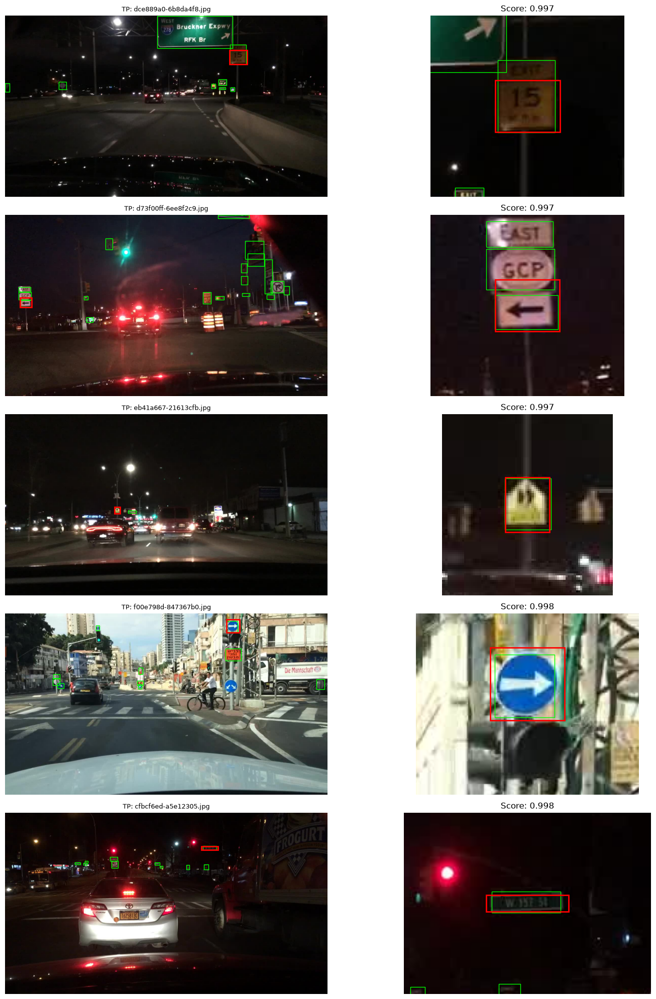

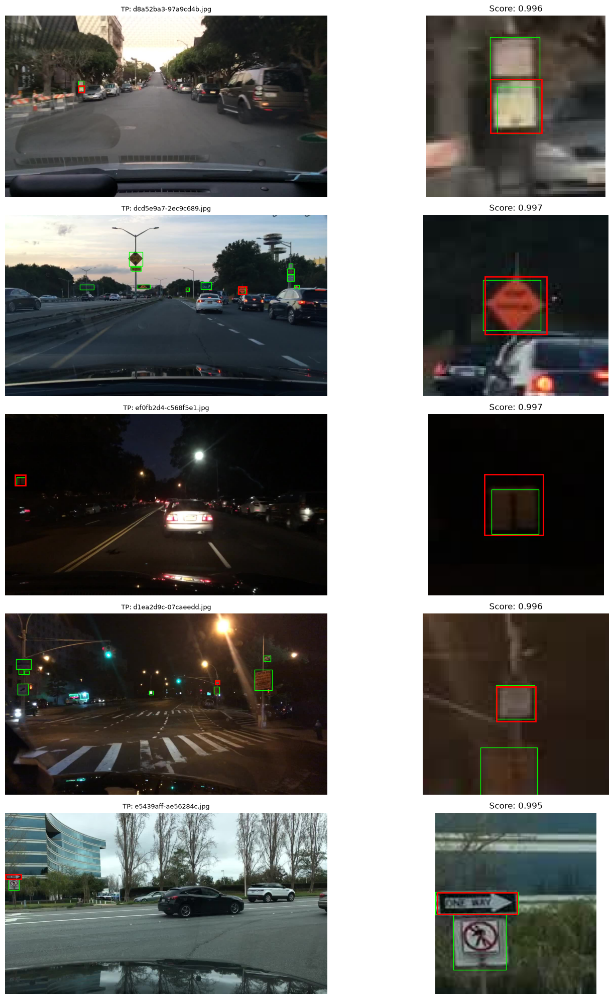

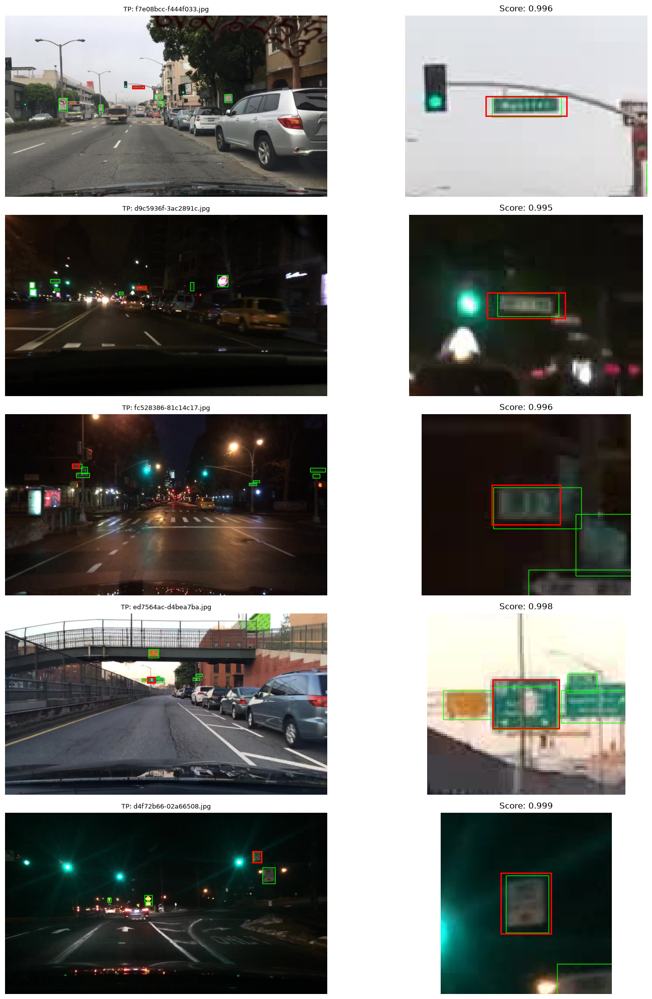

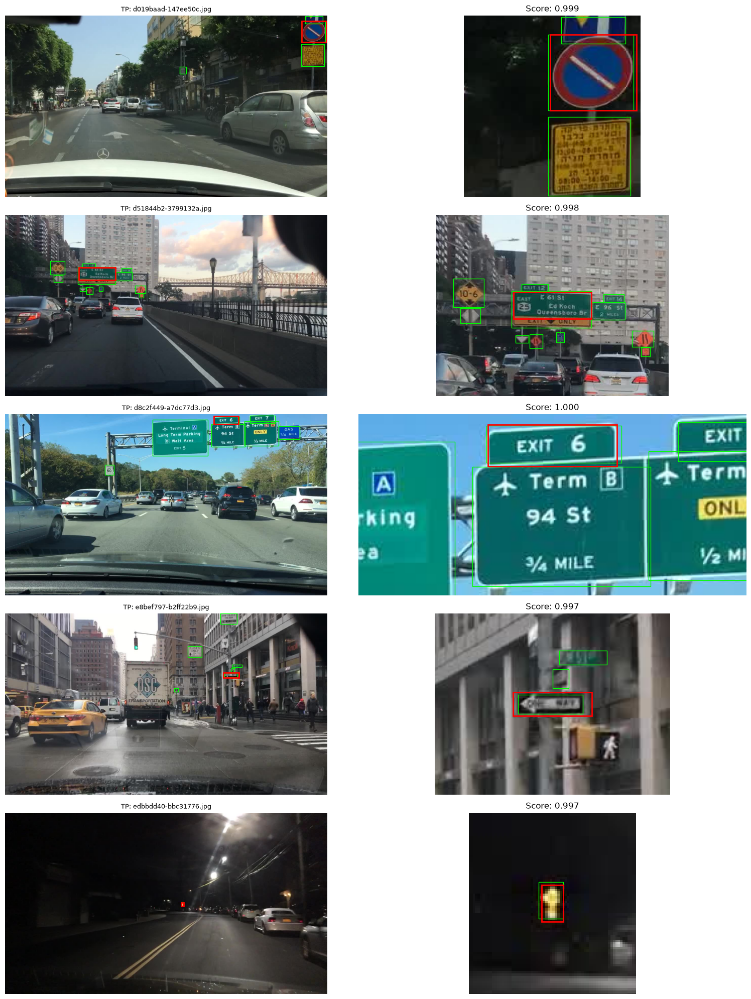

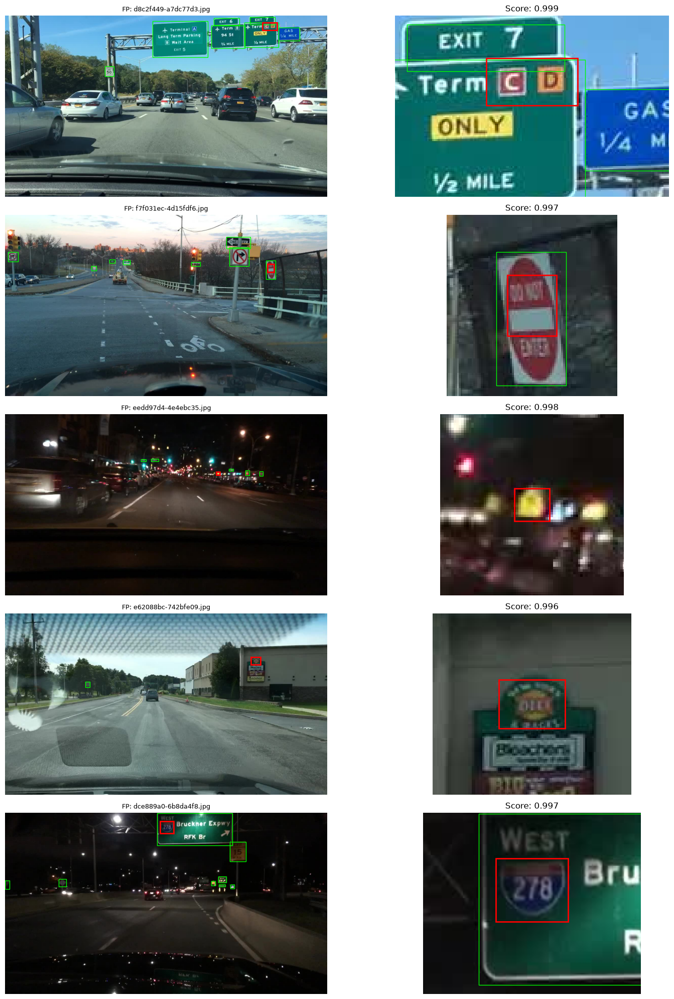

...

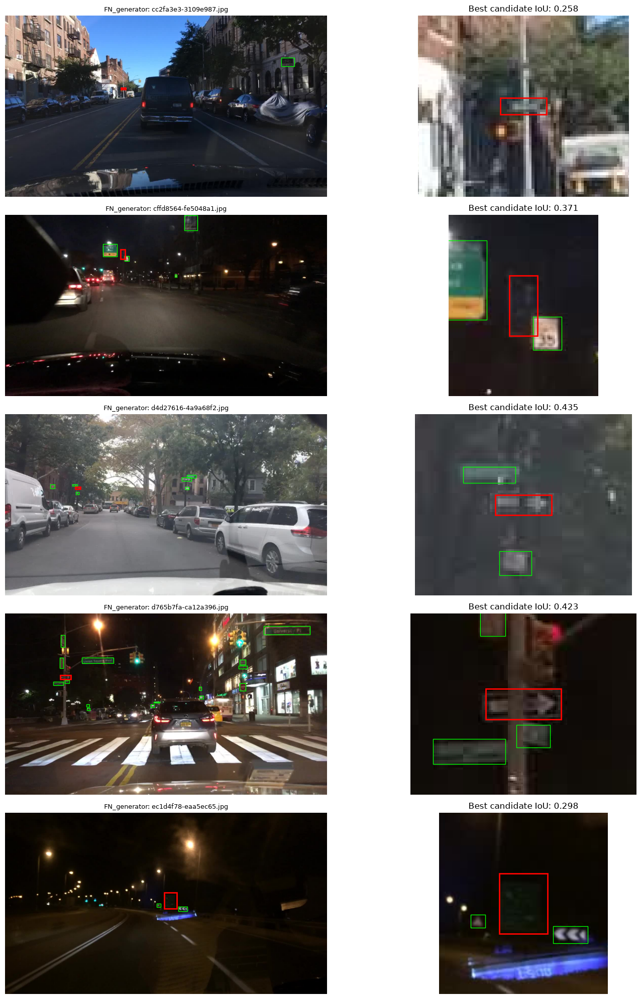

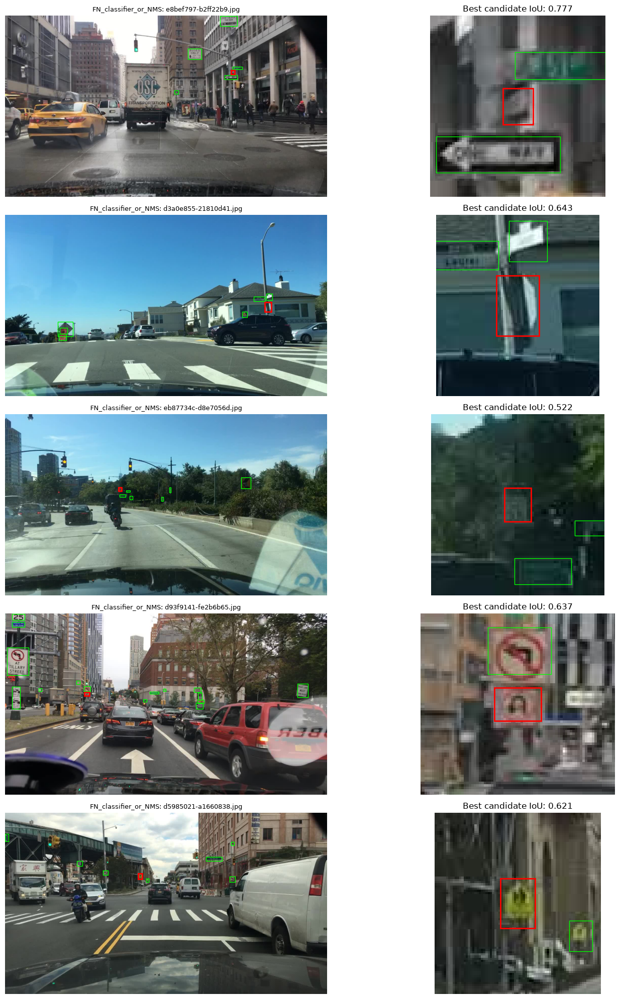

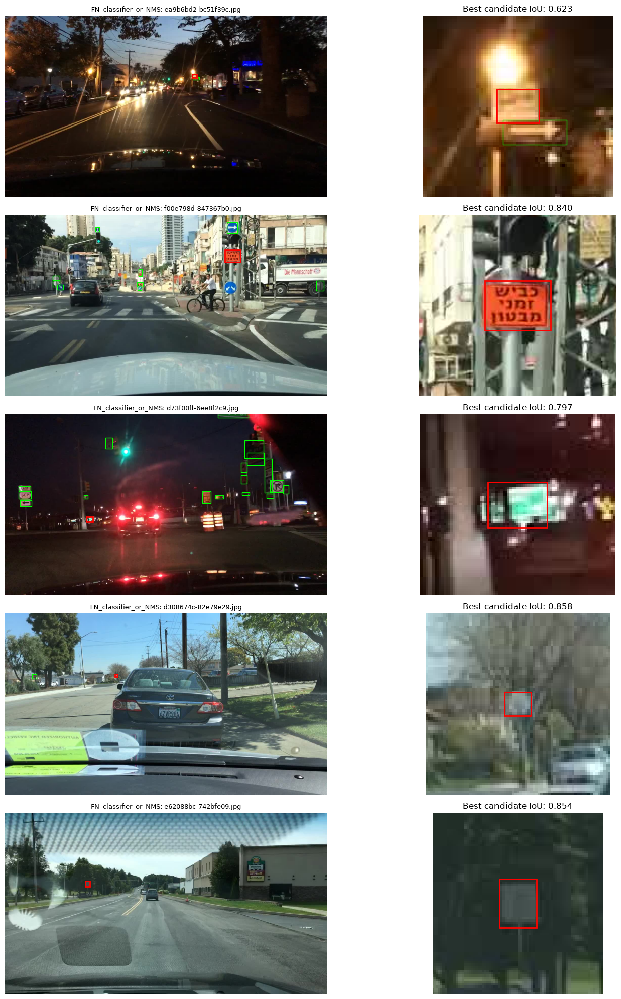

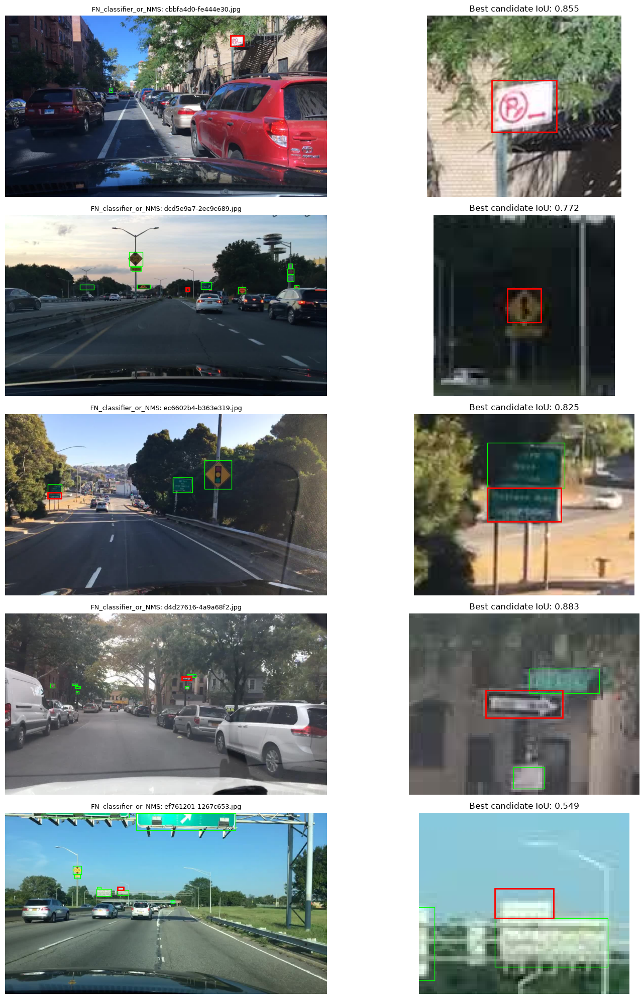

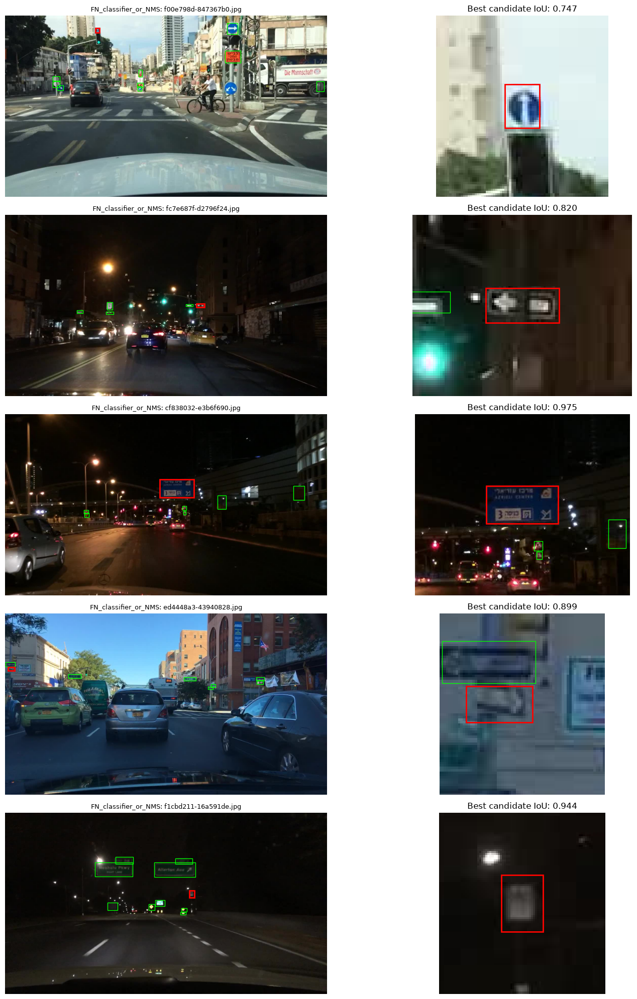

In [15]:
example_rows=[]
for path in test_paths:
    truth=sign_boxes(path)
    proposals,scores=test_predictions[path.name]
    selected=scores>=SCORE_THRESHOLD
    boxes,values=proposals[selected],scores[selected]
    keep=nms(boxes,values)
    boxes,values=boxes[keep],values[keep]
    correct,missed=match_detections(boxes,truth)
    for box,value,matched in zip(boxes,values,correct):
        example_rows.append(dict(image=path.name,kind="TP" if matched else "FP",
            x1=box[0],y1=box[1],x2=box[2],y2=box[3],value=value))
    for index in missed:
        box=truth[index]
        overlap=iou(box,proposals).max(initial=0)
        kind="FN_generator" if overlap<0.5 else "FN_classifier_or_NMS"
        example_rows.append(dict(image=path.name,kind=kind,
            x1=box[0],y1=box[1],x2=box[2],y2=box[3],value=overlap))
examples=pd.DataFrame(example_rows,columns=["image","kind","x1","y1","x2","y2","value"])
examples.to_csv(OUTPUT_DIR / "test_examples.csv",index=False)
display(examples.groupby("kind").size().rename("count"))
for kind in ("TP","FP","FN_generator","FN_classifier_or_NMS"):
    selected=examples[examples["kind"]==kind].sample(frac=1,random_state=42).head(20)
    for start in range(0,len(selected),5):
        page=selected.iloc[start:start+5]
        fig,axes=plt.subplots(len(page),2,figsize=(16,4*len(page)),squeeze=False)
        for axes_row,row in zip(axes,page.itertuples()):
            path=DATA_DIR / "photos/test" / row.image
            image=read_image(path)
            for ax in axes_row:
                ax.imshow(image)
                for box in sign_boxes(path):
                    x1,y1,x2,y2=box
                    ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="lime"))
                ax.add_patch(Rectangle((row.x1,row.y1),row.x2-row.x1,row.y2-row.y1,
                                       fill=False,edgecolor="red",linewidth=2))
                ax.axis("off")
            margin=max(row.x2-row.x1,row.y2-row.y1,30)
            axes_row[1].set_xlim(max(0,row.x1-margin),min(image.shape[1],row.x2+margin))
            axes_row[1].set_ylim(min(image.shape[0],row.y2+margin),max(0,row.y1-margin))
            axes_row[0].set_title(f"{kind}: {row.image}",fontsize=9)
            axes_row[1].set_title(f"{'Score' if kind in ('TP','FP') else 'Best candidate IoU'}: {row.value:.3f}")
        plt.tight_layout()
        plt.show()